In [1]:
from gzip import open as opengz
from os import mkdir, listdir,path
from pandas import read_csv, read_parquet
from os import listdir, path 

In [2]:
def escrituracsv(movimiento:list,angulo,vel,ff=0.35,np=1):
    """La funcion escritura sirve para transformar archivos gz en csv

    Args:
        itera (int): Es la posición de los datos con indices 0,1,2,...,N siendo N la cantiad de archivos en la carpeta contenedora
        paso (int): Es el espaciado con el que se guaran los datos
        movimiento (list): Es el movimiento x,y,z del proyectil
        angulo (float): Es el ángulo con el que impacta el proyectil
        vel (float): velocidad en z del proyectil
        ff (float, optional): Es el  factor de llenado de la cama con la que se simula. Defaults to 0.35.
        np (int, optional): La cantidad de partículas usadas en el proyectil. Defaults to 1.
    """
    ## Definimos la carpeta donde estan los outputs de la sim.
    ruta = f"./erosion_bed_SI_ff_{ff}_np_{np}_vel_{vel}_angle_{angulo}_move_{movimiento[0]}_{movimiento[1]}_{movimiento[2]}"
    for archivo in listdir(ruta):
        if archivo.startswith("output.") and ".gz" in archivo:
            nombre = archivo.replace(".gz","")
            if  not path.isfile(f"{ruta}/{nombre}/{nombre}.csv"): ## Ver si no lo vonvertimos antes
                mkdir(f"{ruta}/{nombre}")
                ## Escirbir archivo ....
                with opengz(f'{ruta}/{archivo}', 'rt', newline='') as csv_file:
                    csv_data = csv_file.read()
                    with open(f'{ruta}/{nombre}/{nombre}.csv', 'wt') as out_file:
                        out_file.write(csv_data)
                print(f"Escritura de: {ruta}/{nombre}/{nombre}.csv\nFue exitosa :)")
            else:
                print(f"Ya existe el archivo {ruta}/{nombre}/{nombre}.csv")
def lecturacsv(itera,paso,movimiento:list,angulo,vel,ff=0.35,np=1):
    """La funcion lectura sirve para abir archivos csv

    Args:
        itera (int): Es la posición de los datos con indices 0,1,2,...,N siendo N la cantiad de archivos en la carpeta contenedora
        paso (int): Es el espaciado con el que se guaran los datos
        movimiento (list): Es el movimiento x,y,z del proyectil
        angulo (float): Es el ángulo con el que impacta el proyectil
        vel (float): velocidad en z del proyectil
        ff (float, optional): Es el  factor de llenado de la cama con la que se simula. Defaults to 0.35.
        np (int, optional): La cantidad de partículas usadas en el proyectil. Defaults to 1.

    Returns:
        pandas.DataFrame: Devuelve un data frame con los datos ["id", "type", "x", "y", "z", "vx", "vy", "vz", "omegax", "omegay", "omegaz", "c_1"]
    """

    return read_csv(f"./erosion_bed_SI_ff_{ff}_np_{np}_vel_{vel}_angle_{angulo}_move_{movimiento[0]}_{movimiento[1]}_{movimiento[2]}/output.{paso*itera}/output.{paso*itera}.csv",skiprows=9,names=["id", "type", "x", "y", "z", "vx", "vy", "vz", "omegax", "omegay", "omegaz", "c_1"],delimiter=" ")
def checkcsv(movimiento:list,angulo,vel,ff=0.35,np=1)->int:
    """Esta funcion cuenta la cantidad de archivos que se transformaron en csv
    Args:
        movimiento (list): Es el movimiento x,y,z del proyectil
        angulo (float): Es el ángulo con el que impacta el proyectil
        vel (float): velocidad en z del proyectil
        ff (float, optional): Es el  factor de llenado de la cama con la que se simula. Defaults to 0.35.
        np (int, optional): La cantidad de partículas usadas en el proyectil. Defaults to 1.
    Returns:
        int: Cantidad de carpetas que hay en el directorio de la simulación
        Paso (int): Cantidad de pasos que salta entre archivos
    """

    ruta = f"./erosion_bed_SI_ff_{ff}_np_{np}_vel_{vel}_angle_{angulo}_move_{movimiento[0]}_{movimiento[1]}_{movimiento[2]}"
    carpetas = [d for d in listdir(ruta) if d.startswith("output.") and not ".gz" in d]
    if not carpetas:
        print("No hay datos registrados todavía.")
        return 0
    return len(carpetas)
def escrituraparquet(movimiento:list,angulo,vel,ff=0.35,np=1):
    """La funcion escritura sirve para transformar archivos csv en parquet

    Args:
        itera (int): Es la posición de los datos con indices 0,1,2,...,N siendo N la cantiad de archivos en la carpeta contenedora
        paso (int): Es el espaciado con el que se guaran los datos
        movimiento (list): Es el movimiento x,y,z del proyectil
        angulo (float): Es el ángulo con el que impacta el proyectil
        vel (float): velocidad en z del proyectil
        ff (float, optional): Es el  factor de llenado de la cama con la que se simula. Defaults to 0.35.
        np (int, optional): La cantidad de partículas usadas en el proyectil. Defaults to 1.
    """

    ## Definimos la carpeta donde estan los outputs de la sim.
    ruta = f"./erosion_bed_SI_ff_{ff}_np_{np}_vel_{vel}_angle_{angulo}_move_{movimiento[0]}_{movimiento[1]}_{movimiento[2]}"
    for archivo in listdir(ruta):
        if archivo.startswith("output."):
            nombre = archivo.replace(".csv","")
            if  not path.isfile(f"{ruta}/{nombre}/{nombre}.parquet"): ## Ver si no lo vonvertimos antes
                ## Escirbir archivo ....
                DF = read_csv(f"{ruta}/{nombre}/{nombre}.csv",skiprows=9,names=["id", "type", "x", "y", "z", "vx", "vy", "vz", "omegax", "omegay", "omegaz", "c_1"],delimiter=" ")
                DF.to_parquet(f"{ruta}/{nombre}/{nombre}.parquet",compression="zstd")
                del DF
                print(f"Escritura de: {ruta}/{nombre}/{nombre}.parquet\nFue exitosa :)")
            else:
                print(f"Ya existe el archivo {ruta}/{nombre}/{nombre}.parquet")
def lecturaparquet(itera,paso,movimiento:list,angulo,vel,ff=0.35,np=1):
    """La funcion lectura sirve para abir archivos parquet

    Args:
        itera (int): Es la posición de los datos con indices 0,1,2,...,N siendo N la cantiad de archivos en la carpeta contenedora
        paso (int): Es el espaciado con el que se guaran los datos
        movimiento (list): Es el movimiento x,y,z del proyectil
        angulo (float): Es el ángulo con el que impacta el proyectil
        vel (float): velocidad en z del proyectil
        ff (float, optional): Es el  factor de llenado de la cama con la que se simula. Defaults to 0.35.
        np (int, optional): La cantidad de partículas usadas en el proyectil. Defaults to 1.

    Returns:
        pandas.DataFrame: Devuelve un data frame con los datos ["id", "type", "x", "y", "z", "vx", "vy", "vz", "omegax", "omegay", "omegaz", "c_1"]
    """

    return read_parquet(f"./erosion_bed_SI_ff_{ff}_np_{np}_vel_{vel}_angle_{angulo}_move_{movimiento[0]}_{movimiento[1]}_{movimiento[2]}/output.{paso*itera}/output.{paso*itera}.parquet",columns=["id", "type", "z", "vx", "vy", "vz"])
def checkparquet(movimiento:list,angulo,vel,ff=0.35,np=1)->int:
    """Esta funcion cuenta la cantidad de archivos que se transformaron en parquet
    Args:
        movimiento (list): Es el movimiento x,y,z del proyectil
        angulo (float): Es el ángulo con el que impacta el proyectil
        vel (float): velocidad en z del proyectil
        ff (float, optional): Es el  factor de llenado de la cama con la que se simula. Defaults to 0.35.
        np (int, optional): La cantidad de partículas usadas en el proyectil. Defaults to 1.
    Returns:
        int: Cantidad de carpetas que hay en el directorio de la simulación
        Paso (int): Cantidad de pasos que salta entre archivos
    """
    ruta = f"./erosion_bed_SI_ff_{ff}_np_{np}_vel_{vel}_angle_{angulo}_move_{movimiento[0]}_{movimiento[1]}_{movimiento[2]}"
    carpetas = [d for d in listdir(ruta) if d.startswith("output.") and not ".gz" in d]
    if not carpetas:
        print("No hay datos registrados todavía.")
        return 0
    return len(carpetas)

In [4]:
import pandas as pd
algo=pd.read_csv("./erosion_bed_SI_ff_0.35_np_1_vel_-10_angle_0_move_0_0_0/output.50000/output.50000.csv",skiprows=9,names=["id", "type", "x", "y", "z", "vx", "vy", "vz", "omegax", "omegay", "omegaz", "c_1"],delimiter=" ")
print("#"*83,"\n"," "*27,"Etiquetas de los data frames\n","#"*83)
print(list(algo.columns))
print("""
id : Es el número de la partícula
type : Es si es cama o proyectil 1 o 2 respectivamente
x , y , z : no necesita introducción
vx , vy , vz : tampoco necesita introducción
omegax , omegay , omegaz : tampoco necesita introducción
c_1 : creo que es la densidad""")



################################################################################### 
                             Etiquetas de los data frames
 ###################################################################################
['id', 'type', 'x', 'y', 'z', 'vx', 'vy', 'vz', 'omegax', 'omegay', 'omegaz', 'c_1']

id : Es el número de la partícula
type : Es si es cama o proyectil 1 o 2 respectivamente
x , y , z : no necesita introducción
vx , vy , vz : tampoco necesita introducción
omegax , omegay , omegaz : tampoco necesita introducción
c_1 : creo que es la densidad


In [5]:
## Escribo los archivos de gz a csv de ser necesario
escrituracsv(movimiento=[0,0,0],angulo=0,vel=-10)
## Escribo los archivos de csv a parquet de ser necesario
escrituraparquet(movimiento=[0,0,0],angulo=0,vel=-10)

Ya existe el archivo ./erosion_bed_SI_ff_0.35_np_1_vel_-10_angle_0_move_0_0_0/output.1200000/output.1200000.parquet
Ya existe el archivo ./erosion_bed_SI_ff_0.35_np_1_vel_-10_angle_0_move_0_0_0/output.1150000/output.1150000.parquet
Ya existe el archivo ./erosion_bed_SI_ff_0.35_np_1_vel_-10_angle_0_move_0_0_0/output.450000/output.450000.parquet
Ya existe el archivo ./erosion_bed_SI_ff_0.35_np_1_vel_-10_angle_0_move_0_0_0/output.1050000/output.1050000.parquet
Ya existe el archivo ./erosion_bed_SI_ff_0.35_np_1_vel_-10_angle_0_move_0_0_0/output.1250000/output.1250000.parquet
Ya existe el archivo ./erosion_bed_SI_ff_0.35_np_1_vel_-10_angle_0_move_0_0_0/output.1000000/output.1000000.parquet
Ya existe el archivo ./erosion_bed_SI_ff_0.35_np_1_vel_-10_angle_0_move_0_0_0/output.300000/output.300000.parquet
Ya existe el archivo ./erosion_bed_SI_ff_0.35_np_1_vel_-10_angle_0_move_0_0_0/output.100000/output.100000.parquet
Ya existe el archivo ./erosion_bed_SI_ff_0.35_np_1_vel_-10_angle_0_move_0_0_0/

In [36]:
import numexpr as ne
import pandas as pd
import numpy as np
import os

movimiento = [0,0,0]
angulo = 0 
vel = -10
threshold = 0.004

# Asumo que ya tienes tu función checkparquet importada o definida
LenTotal, paso = checkparquet(movimiento, angulo, vel), 50000

# Pre-allocating lists is slightly faster, but lists are okay for <100k iters
Data_collect = {
    "K": [], 
    "Max": [], 
    "Min":[],
    "Vcm": [], 
    "N": 0, 
    "Eyección": [],
    "Eyectados_K":[]
}

# Variables constantes fuera del bucle
v0 = 0
N = 0
altura = 0

print(f"Iniciando análisis de {LenTotal} archivos...")

for i in range(LenTotal):
    # 1. Lectura de los datos con las columnas ["id","type","z","vx","vy","vz"]
    Datos = lecturaparquet(i, paso, movimiento, angulo, vel)
    
    # 2. Convertir a Numpy Arrays INMEDIATAMENTE
    # Esto elimina el overhead de Pandas para las operaciones matemáticas siguientes
    vx = Datos["vx"].to_numpy()
    vy = Datos["vy"].to_numpy()
    vz = Datos["vz"].to_numpy()
    z_pos = Datos["z"].to_numpy()
    types = Datos["type"].to_numpy(dtype=np.int8)

    # Lógica de inicialización (solo primer frame)
    if i == 0:
        # Buscamos la altura de la cama
        altura = z_pos[types == 1].max()
        # Buscamos si la primera salida output.0 tiene el proyectil o no
        mask_proyectil = (types == 2)
        if not np.any(mask_proyectil):
            # Añadimos lods datos del proyectil en caso de no estar
            v0_actual = vel 
            N = len(types) + 1
            Data_collect["N"] = N
        else:
            # En caso de que esté no añadimos más
            v0_actual = 0
            N = len(types) 
            Data_collect["N"] = N
    else:
        # En los siguientes outputs ya deberia aparecer el proyectil
        v0_actual = 0 

    # Calculamos la velocidad del CM
    vcm_x = np.sum(vx) / N
    vcm_y = np.sum(vy) / N
    vcm_z = (np.sum(vz) + v0_actual) / N
    
    Data_collect["Vcm"].append([vcm_x, vcm_y, vcm_z])
    # Calculo módulo velocidad relativa
    Vnorm2 = ne.evaluate("(vx - vcm_x)**2 + (vy - vcm_y)**2 + (vz - vcm_z)**2")
    
    # Energía Cinética
    Data_collect["K"].append(0.5 * np.sum(Vnorm2))
    # Filtro para ver cuales se salieron de la cama
    filtro = (z_pos > altura) & (vz > threshold)
    # Max / Min
    Data_collect["Max"].append(np.max(Vnorm2[~filtro]))
    Data_collect["Min"].append(np.min(Vnorm2[~filtro]))
    # Contamos cuantos salieron y su energía
    count_eyeccion = np.sum(filtro)
    Data_collect["Eyección"].append(count_eyeccion)
    Data_collect["Eyectados_K"].append( 0.5 * np.sum(Vnorm2[filtro]))


Iniciando análisis de 27 archivos...


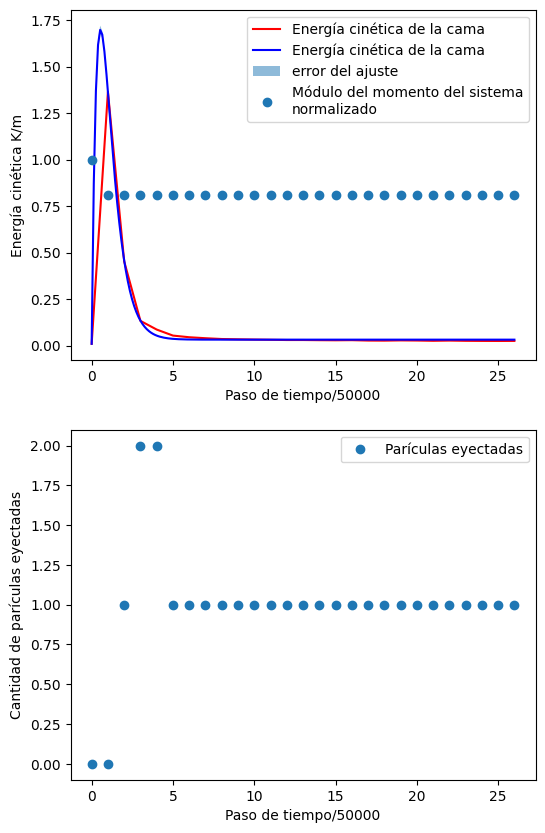

In [34]:
import matplotlib.pyplot as plt 
import numpy as np
from scipy.optimize import curve_fit
## Definimos el modelo que queremos ajustar
def modelo(x,a,b,c,d):
    return a*(x-d)*np.exp(-b*(x-d))+c
## Le sacamos las derivadas aprciales respecto  a los parámetros que le queremos ajustar
def derA(x,a,b,c,d):
    return (x-d)*np.exp(-b*(x-d))
def derB(x,a,b,c,d):
    return -a*(x-d)**2*np.exp(-b*(x-d))
def derC(x,a,b,c,d):
    return 1
def derD(x,a,b,c,d):
    return a*(b*(x-d)-1)*np.exp(-b*(x-d))
## Definimos el gradiente 
def grad(x,popt):
    return np.array([derA(x,*popt),derB(x,*popt),derC(x,*popt),derD(x,*popt)])
## Buscamos la desviación estandar del ajuste usando la matriz de covarianza
def errorf(absisa,popt,pcov):
    return np.array([np.sqrt(grad(x,popt).T @ pcov @ grad(x,popt)) if x!=0 else 0 for x in absisa])
## Energía de las partículas de la cama menos el proyectil a t=0
K = np.array(Data_collect["K"])

## Hacemos el ajuste
popt, pcov = curve_fit(modelo,np.linspace(0,26,27),K,sigma=y_err)

## Velocidad del CM a tiempo t
vx , vy , vz = np.array(Data_collect['Vcm'])[:,0] , np.array(Data_collect['Vcm'])[:,1] , np.array(Data_collect['Vcm'])[:,2]

## Para hacer el plot continuo
X = np.linspace(0,26,200)

#########################################
# Plots #################################
#########################################
fig,ax = plt.subplots(2,1,figsize=(6,10))
ax[0].plot(K,"r-",label="Energía cinética de la cama")
ax[0].plot(X,modelo(X,*popt),"b-",label="Energía cinética de la cama")
ax[0].fill_between(X,modelo(X,*popt)-errorf(X,popt,pcov),modelo(X,*popt)+errorf(X,popt,pcov),alpha=0.5,label=r"error del ajuste")
ax[0].plot((vx**2+vy**2+vz**2)/max((vx**2+vy**2+vz**2)),"o",label="Módulo del momento del sistema\nnormalizado")
ax[0].legend()
ax[0].set_xlabel("Paso de tiempo/50000")
ax[0].set_ylabel("Energía cinética K/m")

ax[1].plot(Data_collect['Eyección'],"o",label="Parículas eyectadas")
ax[1].set_xlabel("Paso de tiempo/50000")
ax[1].set_ylabel("Cantidad de parículas eyectadas")
ax[1].legend()


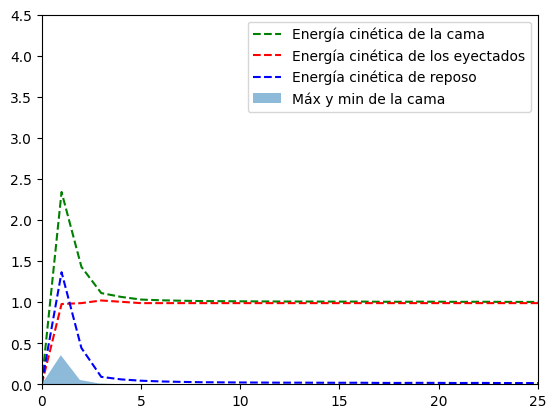

In [37]:

K_cama = np.array(Data_collect["K"])
K_eyectados = np.array(Data_collect['Eyectados_K'])

plt.plot(K_cama,"g--",label="Energía cinética de la cama")
plt.plot(K_eyectados,"r--",label="Energía cinética de los eyectados")
plt.plot(K_cama-K_eyectados,"b--",label="Energía cinética de reposo")
plt.fill_between(np.linspace(0,25,27),np.array(Data_collect["Min"])*0.5,np.array(Data_collect["Max"])*0.5,alpha=0.5,label=r"Máx y min de la cama")

plt.xlim((0,25))
plt.ylim((0,4.5))
plt.legend()

In [ ]:
#%matplotlib qt
%matplotlib inline

fig = plt.figure()
ax = fig.add_subplot(111,projection="3d")
ax.plot(vx,vy,zs=vz)

In [ ]:
plt.plot(vx,label="x")
plt.plot(vy,label="y")
plt.plot(vz,label="z")
plt.legend()

In [ ]:
# Source - https://stackoverflow.com/a
# Posted by Mr. T, modified by community. See post 'Timeline' for change history
# Retrieved 2025-11-27, License - CC BY-SA 3.0

from scipy.optimize import curve_fit
import numpy as np
def smooth_data_v1(x_arr,y_arr):
    def func(x, a, b, c):
        return a*np.exp(-b*x)+c

    #create the weighting array
    y_weight = np.empty(len(y_arr))
    print(y_weight)
    #high pseudo-sd values, meaning less weighting in the fit
    y_weight.fill(10)
    print(y_weight)
    #low values for point 0 and the last points, meaning more weighting during the fit procedure 
    y_weight[0] = y_weight[-5:-1] = 0.1
    print(y_weight)
    popt, pcov = curve_fit(func, x_arr, y_arr, p0=(y_arr[0], 1, 1), sigma = y_weight, absolute_sigma = True)
    print("a, b, c:", *popt)
    y_smooth = func(x_arr, *popt)

    return y_smooth


x_orig = np.asarray([  0,   1,   2,   3,   4,   5,   6,   7,   8,   9,  10,  11,  12,  13,  14])
y_orig = np.asarray([ 445057,  447635,  450213,  425089,  391746,  350725,  285433,  269027,
  243835,  230587,  216757,  202927,  189097,  175267,  161437])
plt.plot(x_orig,y_orig,"o")
print(smooth_data_v1(x_orig, y_orig))
